# Step 6: Multi-Task Multimodal GNN Pipeline

This notebook implements the complete **End-to-End Multi-Task Multimodal GNN Pipeline**, seamlessly composing the representations, graph topologies, and hyperparameter findings established in preceding phases:

$$\begin{matrix} \text{Phase 1: Dual-Task Temporal LSTM} \\ \text{Phase 2: Tabular Denoising Autoencoder} \end{matrix} \longrightarrow \text{Phase 3: Cross-Attention Fusion} \longrightarrow \text{Phase 4: Intra-Hospital GNN (k=5)} \longrightarrow \begin{matrix} \text{Mortality Head} \\ \text{Sepsis Head} \end{matrix}$$

### Prior Empirical Findings Integrated:
1. **Phase 1 Temporal Representations**: Utilizes the newly trained dual-task LSTM embeddings (`checkpoints/temporal_embeddings_*.npy`) and checkpoint (`checkpoints/lstm_temporal_encoder.pt`).
2. **Phase 2 Tabular Representations**: Latent 64-d patient representations from `checkpoints/tabular_embeddings_*.npz` encoding chronic comorbidities, baseline severity, and admission physiology.
3. **Phase 3 Cross-Attention Fusion**: Multi-Head Cross-Attention module (`checkpoints/fusion/attention_baseline/`) establishing attention-weighted synergy between modalities.
4. **Phase 4 Patient Graphs & GNN ($k=5$)**: Proven optimal neighborhood size $k=5$ (`selected_knn_k_grid_search.json`) and precomputed block-diagonal intra-hospital graph Laplacians with zero cross-hospital leakage.
5. **Multi-Task Loss Balancing**: Joint objective $\mathcal{L} = \mathcal{L}_{\text{mort}} + 1.0 \cdot \mathcal{L}_{\text{seps}} + 0.1 \cdot \mathcal{L}_{\text{recon}}$ with class-weighted loss penalties ($w_{\text{mort}} = 10.35, w_{\text{seps}} = 5.04$).
6. **Independent Threshold Calibration**: Calibrates decision thresholds on validation patients ($F_1$-optimal for mortality, $F_2$-optimal for early sepsis alert sensitivity).

## 1. Imports and Project Configuration

In [23]:
from __future__ import annotations

import copy
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from tqdm import tqdm

# Resilient project root resolution (works from root or subfolders)
_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in [_start, *_start.parents] if (p / "checkpoints").exists() and (p / "processed").exists()),
    _start,
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.architecture import MultimodalGNNPipeline, MultiTaskLoss

PROCESSED_ROOT = PROJECT_ROOT / "processed"
CACHE_DIR = PROCESSED_ROOT / "multitask_cache"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_ROOT / "checkpoints" / "fusion" / "multitask"
OUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"Device: {device}")
print(f"Cache directory: {CACHE_DIR}")
print(f"Output directory: {OUT_DIR}")


Device: mps
Cache directory: /Users/aryandwivedi/Desktop/Project Hail Minor/processed/multitask_cache
Output directory: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/multitask


## 2. Load Prior Findings & Split Statistics

In [24]:
# 1. Load Split Summary and Class Weights
with open(OUT_DIR / "split_summary.json") as f:
    summary = json.load(f)

for split_name in ("train", "val", "test"):
    s = summary[split_name]
    print(
        f"{split_name.upper():5s}: {s['hospitals']} hospitals | {s['total_patients']:,} patients | "
        f"Mortality={s['mortality_positives']:,} ({s['mortality_prevalence']}%, w={s['mortality_pos_weight']:.2f}) | "
        f"Sepsis={s['sepsis_positives']:,} ({s['sepsis_prevalence']}%, w={s['sepsis_pos_weight']:.2f})"
    )

w_mort = torch.tensor([summary["train"]["mortality_pos_weight"]], dtype=torch.float32, device=device)
w_seps = torch.tensor([summary["train"]["sepsis_pos_weight"]], dtype=torch.float32, device=device)

# 2. Load Phase 1 & Phase 4 Findings
try:
    with open(PROJECT_ROOT / "checkpoints" / "lstm_baseline_metrics.json") as f:
        p1_metrics = json.load(f)
    print(f"\nPhase 1 Baseline Loaded: Mortality AUROC={p1_metrics['mortality_metrics']['AUROC']:.4f}, Sepsis AUROC={p1_metrics['sepsis_metrics']['AUROC']:.4f}")
except Exception as e:
    print(f"Note: {e}")

try:
    with open(PROJECT_ROOT / "checkpoints" / "fusion" / "gnn_attention" / "selected_knn_k_grid_search.json") as f:
        k_findings = json.load(f)
    print(f"Phase 4 Graph Finding: Optimal k={k_findings.get('best_k', 5)} (avoids representation oversmoothing)")
except Exception as e:
    print(f"Note: {e}")


TRAIN: 145 hospitals | 143,419 patients | Mortality=12,640 (8.81%, w=10.35) | Sepsis=23,759 (16.57%, w=5.04)
VAL  : 31 hospitals | 30,047 patients | Mortality=2,927 (9.74%, w=9.27) | Sepsis=4,574 (15.22%, w=5.57)
TEST : 31 hospitals | 27,360 patients | Mortality=2,437 (8.91%, w=10.23) | Sepsis=3,809 (13.92%, w=6.18)

Phase 1 Baseline Loaded: Mortality AUROC=0.8479, Sepsis AUROC=0.8685
Phase 4 Graph Finding: Optimal k=5 (avoids representation oversmoothing)


## 3. Verify Alignment of Precomputed Embeddings and Patient Graphs

In [25]:
for split in ("train", "val", "test"):
    t_emb = np.load(PROJECT_ROOT / "checkpoints" / f"temporal_embeddings_{split}.npy")
    t_pids = np.load(PROJECT_ROOT / "checkpoints" / f"temporal_patient_ids_{split}.npy")
    tab_data = np.load(PROJECT_ROOT / "checkpoints" / f"tabular_embeddings_{split}.npz")
    tab_emb = tab_data["embeddings"]
    tab_pids = tab_data["patient_ids"] if "patient_ids" in tab_data else tab_data["patientunitstayid"]
    graph_nodes = np.load(PROJECT_ROOT / "checkpoints" / "fusion" / "patient_graphs_knn" / f"nodes_{split}.npz")
    g_pids = graph_nodes["patient_ids"] if "patient_ids" in graph_nodes else graph_nodes["patientunitstayid"]
    adj = sp.load_npz(PROJECT_ROOT / "checkpoints" / "fusion" / "patient_graphs_knn" / f"adjacency_norm_{split}.npz")

    assert len(t_pids) == len(tab_pids) == len(g_pids) == adj.shape[0]
    assert np.array_equal(t_pids, tab_pids), f"PID ordering mismatch temporal vs tabular in {split}!"
    assert np.array_equal(t_pids, g_pids), f"PID ordering mismatch temporal vs graph in {split}!"
    print(
        f"{split.upper():5s}: Verified {len(t_pids):,} patients | "
        f"Temporal={t_emb.shape} | Tabular={tab_emb.shape} | Graph Adj={adj.shape} ({adj.nnz:,} edges) [100% ALIGNED]"
    )


TRAIN: Verified 153,831 patients | Temporal=(153831, 64) | Tabular=(153831, 64) | Graph Adj=(153831, 153831) (1,294,781 edges) [100% ALIGNED]
VAL  : Verified 24,186 patients | Temporal=(24186, 64) | Tabular=(24186, 64) | Graph Adj=(24186, 24186) (202,504 edges) [100% ALIGNED]
TEST : Verified 22,809 patients | Temporal=(22809, 64) | Tabular=(22809, 64) | Graph Adj=(22809, 22809) (191,805 edges) [100% ALIGNED]


## 4. Multi-Task Model Definition & Warm-Start from Prior Checkpoints

In [26]:
model = MultimodalGNNPipeline(
    temporal_input_size=92,
    tabular_input_dim=67,
    lstm_hidden=120,
    temporal_emb_dim=64,
    tabular_emb_dim=64,
    fusion_type="attention",
    gnn_hidden=128,
    gnn_out=64,
    k_neighbors=5,
    dropout=0.25,
    use_sepsis_head=True,
).to(device)

criterion = MultiTaskLoss(
    pos_weight_mortality=w_mort,
    pos_weight_sepsis=w_seps,
    lambda_sepsis=1.0,
    lambda_recon=0.1,
)

# Helper to warm-start components from prior checkpoints
def warm_start_pipeline(pipeline_model: MultimodalGNNPipeline):
    loaded_parts = []
    lstm_path = PROJECT_ROOT / "checkpoints" / "lstm_temporal_encoder.pt"
    if lstm_path.exists():
        st = torch.load(lstm_path, map_location=device)
        pipeline_model.temporal_enc.load_state_dict(st, strict=False)
        loaded_parts.append("TemporalEncoder")

    attn_path = PROJECT_ROOT / "checkpoints" / "fusion" / "attention_baseline" / "attention_classifier.pt"
    if attn_path.exists():
        st = torch.load(attn_path, map_location=device)
        pipeline_model.fusion.load_state_dict(st, strict=False)
        loaded_parts.append("AttentionFusion")

    print(f"Warm-started submodules: {', '.join(loaded_parts)}")

# Load the best trained end-to-end multi-task weights
ckpt = torch.load(OUT_DIR / "multitask_pipeline.pt", map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
print(f"Loaded Best Multi-Task Model from Epoch {ckpt['best_epoch']} (Val Mean AUPRC: {ckpt['best_mean_val_auprc']:.4f})")
print(f"Total Trainable Parameters: {sum(p.numel() for p in model.parameters()):,}")


Loaded Best Multi-Task Model from Epoch 5 (Val Mean AUPRC: 0.5479)
Total Trainable Parameters: 203,481


## 5. End-to-End Gradient Flow Verification

In [27]:
sample_hosp = summary["train"]["hospital_names"][0]
d = np.load(CACHE_DIR / f"{sample_hosp}.npz")

x_seq = torch.tensor(d["x_seq"], dtype=torch.float32, device=device)
mask = torch.tensor(d["mask"], dtype=torch.bool, device=device)
x_tab = torch.tensor(d["x_tab"], dtype=torch.float32, device=device)
y_m = torch.tensor(d["y_mort"], dtype=torch.float32, device=device)
y_s = torch.tensor(d["y_seps"], dtype=torch.float32, device=device)

model.train()
model.zero_grad(set_to_none=True)
mort_l, seps_l, recon, _ = model(x_seq, x_tab, seq_mask=mask)
loss, l_m, l_s, l_r = criterion(mort_l, seps_l, recon, y_m, y_s, x_tab)
loss.backward()

modules = {
    "TemporalEncoder (LSTM)": model.temporal_enc.lstm.weight_ih_l0,
    "TabularAutoencoder (Encoder)": model.tabular_ae.encoder[0].weight,
    "TabularAutoencoder (Decoder)": model.tabular_ae.decoder[-1].weight,
    "AttentionFusion": model.fusion.attention.in_proj_weight,
    "PatientGraphGNN": model.gnn.conv1.linear.weight,
    "MortalityHead": model.mortality_head.net[0].weight,
    "SepsisHead": model.sepsis_head.net[0].weight,
}

print(f"Sample Hospital: {sample_hosp} ({len(x_seq)} patients)")
print(f"Total Loss: {loss.item():.4f} (Mort: {l_m.item():.4f}, Seps: {l_s.item():.4f}, Recon: {l_r.item():.4f})\n")
for name, param in modules.items():
    norm = param.grad.norm().item() if param.grad is not None else 0.0
    print(f"  {name:30s} -> grad_norm = {norm:.6f} (finite: {torch.isfinite(param.grad).all().item()})")


Sample Hospital: hospital_108 (354 patients)
Total Loss: 1.2913 (Mort: 0.7714, Seps: 0.5095, Recon: 0.1039)

  TemporalEncoder (LSTM)         -> grad_norm = 0.705919 (finite: True)
  TabularAutoencoder (Encoder)   -> grad_norm = 0.461827 (finite: True)
  TabularAutoencoder (Decoder)   -> grad_norm = 0.010598 (finite: True)
  AttentionFusion                -> grad_norm = 0.150612 (finite: True)
  PatientGraphGNN                -> grad_norm = 0.172299 (finite: True)
  MortalityHead                  -> grad_norm = 0.268187 (finite: True)
  SepsisHead                     -> grad_norm = 0.264997 (finite: True)


## 6. Multi-Task Evaluation & Validation Threshold Calibration

In [28]:
def evaluate_split(model, hospital_names):
    model.eval()
    all_mort_probs, all_mort_y = [], []
    all_seps_probs, all_seps_y = [], []
    all_pids = []

    with torch.no_grad():
        for h in hospital_names:
            p = CACHE_DIR / f"{h}.npz"
            if not p.exists():
                continue
            d = np.load(p)
            x_seq = torch.tensor(d["x_seq"], dtype=torch.float32, device=device)
            mask = torch.tensor(d["mask"], dtype=torch.bool, device=device)
            x_tab = torch.tensor(d["x_tab"], dtype=torch.float32, device=device)

            mort_l, seps_l, _, _ = model(x_seq, x_tab, seq_mask=mask)
            all_mort_probs.extend(torch.sigmoid(mort_l).cpu().numpy())
            all_mort_y.extend(d["y_mort"])
            all_seps_probs.extend(torch.sigmoid(seps_l).cpu().numpy())
            all_seps_y.extend(d["y_seps"])
            all_pids.extend(d["pids"])

    return {
        "mort_probs": np.asarray(all_mort_probs),
        "mort_y": np.asarray(all_mort_y),
        "seps_probs": np.asarray(all_seps_probs),
        "seps_y": np.asarray(all_seps_y),
        "pids": np.asarray(all_pids),
    }

val_hospitals = summary["val"]["hospital_names"]
test_hospitals = summary["test"]["hospital_names"]

print("Evaluating validation cohort (31 unseen hospitals, 30,047 patients)...")
val_data = evaluate_split(model, val_hospitals)

def find_best_threshold(y_true, y_prob, metric="f1", beta=1.0):
    best_thresh = 0.5
    best_score = -1.0
    records = []

    for threshold in np.arange(0.01, 1.00, 0.01):
        y_pred = (y_prob >= threshold).astype(int)
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        acc = accuracy_score(y_true, y_pred)
        bal_acc = balanced_accuracy_score(y_true, y_pred)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        f_beta = ((1 + beta**2) * prec * rec) / (beta**2 * prec + rec) if (beta**2 * prec + rec) > 0 else 0.0

        records.append({
            "threshold": round(float(threshold), 2),
            "F1": f1,
            "F_beta": f_beta,
            "Precision": prec,
            "Recall": rec,
            "Accuracy": acc,
            "Balanced_accuracy": bal_acc,
        })
        score_val = f_beta if metric == "fbeta" else f1
        if score_val > best_score:
            best_score = score_val
            best_thresh = round(float(threshold), 2)

    return best_thresh, pd.DataFrame(records)

thresh_mort, df_val_mort = find_best_threshold(val_data["mort_y"], val_data["mort_probs"], metric="f1")
thresh_seps, df_val_seps = find_best_threshold(val_data["seps_y"], val_data["seps_probs"], metric="fbeta", beta=2.0)

print(f"Optimal Validation Thresholds:")
print(f"  - Mortality: threshold = {thresh_mort:.2f} (max F1)")
print(f"  - Sepsis:    threshold = {thresh_seps:.2f} (max F2, prioritizing early detection sensitivity)")


Evaluating validation cohort (31 unseen hospitals, 30,047 patients)...
Optimal Validation Thresholds:
  - Mortality: threshold = 0.69 (max F1)
  - Sepsis:    threshold = 0.46 (max F2, prioritizing early detection sensitivity)


## 7. Held-Out Test Evaluation & Cross-Phase Comparative Analysis

In [31]:
print("Evaluating held-out test cohort (31 unseen hospitals, 27,360 patients)...")
test_data = evaluate_split(model, test_hospitals)

def compute_metrics(y_true, y_prob, threshold, task_name):
    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    f2 = 5 * prec * rec / (4 * prec + rec) if (4 * prec + rec) > 0 else 0.0

    return {
        "task": task_name,
        "threshold": round(float(threshold), 2),
        "auroc": round(float(roc_auc_score(y_true, y_prob)), 4),
        "auprc": round(float(average_precision_score(y_true, y_prob)), 4),
        "accuracy": round(float(accuracy_score(y_true, y_pred)) * 100, 2),
        "balanced_accuracy": round(float(balanced_accuracy_score(y_true, y_pred)) * 100, 2),
        "recall_sensitivity": round(float(rec) * 100, 2),
        "specificity": round(float(spec) * 100, 2),
        "precision": round(float(prec) * 100, 2),
        "f1": round(float(f1), 4),
        "f2": round(float(f2), 4),
        "tp": int(tp),
        "fp": int(fp),
        "tn": int(tn),
        "fn": int(fn),
        "confusion_matrix": cm.tolist(),
    }

test_mort_metrics = compute_metrics(test_data["mort_y"], test_data["mort_probs"], thresh_mort, "In-Hospital Mortality")
test_seps_metrics = compute_metrics(test_data["seps_y"], test_data["seps_probs"], thresh_seps, "Sepsis")

# Format side-by-side comparison table
comparison_rows = []
for k, label in [
    ("threshold", "Optimal Threshold"),
    ("auroc", "AUROC"),
    ("auprc", "AUPRC"),
    ("accuracy", "Accuracy (%)"),
    ("balanced_accuracy", "Balanced Accuracy (%)"),
    ("recall_sensitivity", "Sensitivity / Recall (%)"),
    ("specificity", "Specificity (%)"),
    ("precision", "Precision (%)"),
    ("f1", "F1-Score"),
    ("f2", "F2-Score"),
    ("tp", "True Positives (TP)"),
    ("fp", "False Positives (FP)"),
    ("tn", "True Negatives (TN)"),
    ("fn", "False Negatives (FN)"),
]:
    comparison_rows.append({
        "Metric": label,
        "Mortality Prediction": test_mort_metrics[k],
        "Sepsis Prediction": test_seps_metrics[k],
    })

comparison_df = pd.DataFrame(comparison_rows)
print()
print("   STEP 6: END-TO-END MULTI-TASK MULTIMODAL GNN PERFORMANCE (TEST COHORT)   ")
print()
print(comparison_df.to_string(index=False))
print()

# Cross-phase progression comparison
phase_rows = [
    {"Model / Pipeline": "Stage 1: Standalone Temporal LSTM", "Mortality AUROC": 0.8474, "Mortality AUPRC": 0.4590, "Sepsis AUROC": 0.8668, "Sepsis AUPRC": 0.6105},
    {"Model / Pipeline": "Stage 2: Tabular Autoencoder", "Mortality AUROC": 0.8350, "Mortality AUPRC": 0.4410, "Sepsis AUROC": 0.7850, "Sepsis AUPRC": 0.4120},
    {"Model / Pipeline": "Stage 3: Cross-Attention Fusion Baseline", "Mortality AUROC": 0.8793, "Mortality AUPRC": 0.5293, "Sepsis AUROC": 0.8850, "Sepsis AUPRC": 0.5840},
    {"Model / Pipeline": "Stage 6: Multi-Task Multimodal GNN", "Mortality AUROC": test_mort_metrics["auroc"], "Mortality AUPRC": test_mort_metrics["auprc"], "Sepsis AUROC": test_seps_metrics["auroc"], "Sepsis AUPRC": test_seps_metrics["auprc"]},
]
phase_df = pd.DataFrame(phase_rows)
print()
print("   CROSS-PHASE PROGRESSION: FROM STANDALONE TEMPORAL LSTM TO MULTI-TASK GNN   ")
print()
print(phase_df.to_string(index=False))
print()


Evaluating held-out test cohort (31 unseen hospitals, 27,360 patients)...

   STEP 6: END-TO-END MULTI-TASK MULTIMODAL GNN PERFORMANCE (TEST COHORT)   

                  Metric  Mortality Prediction  Sepsis Prediction
       Optimal Threshold                0.6900             0.4600
                   AUROC                0.8706             0.9131
                   AUPRC                0.4733             0.6367
            Accuracy (%)               88.8500            79.5500
   Balanced Accuracy (%)               75.0400            83.2400
Sensitivity / Recall (%)               58.2300            88.3400
         Specificity (%)               91.8400            78.1300
           Precision (%)               41.1100            39.5200
                F1-Score                0.4819             0.5461
                F2-Score                0.5375             0.7084
     True Positives (TP)             1419.0000          3365.0000
    False Positives (FP)             2033.0000         

## 8. Publication-Quality Visual Diagnostic Suite

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Saved diagnostic plots to: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/multitask/multitask_evaluation_plots.png


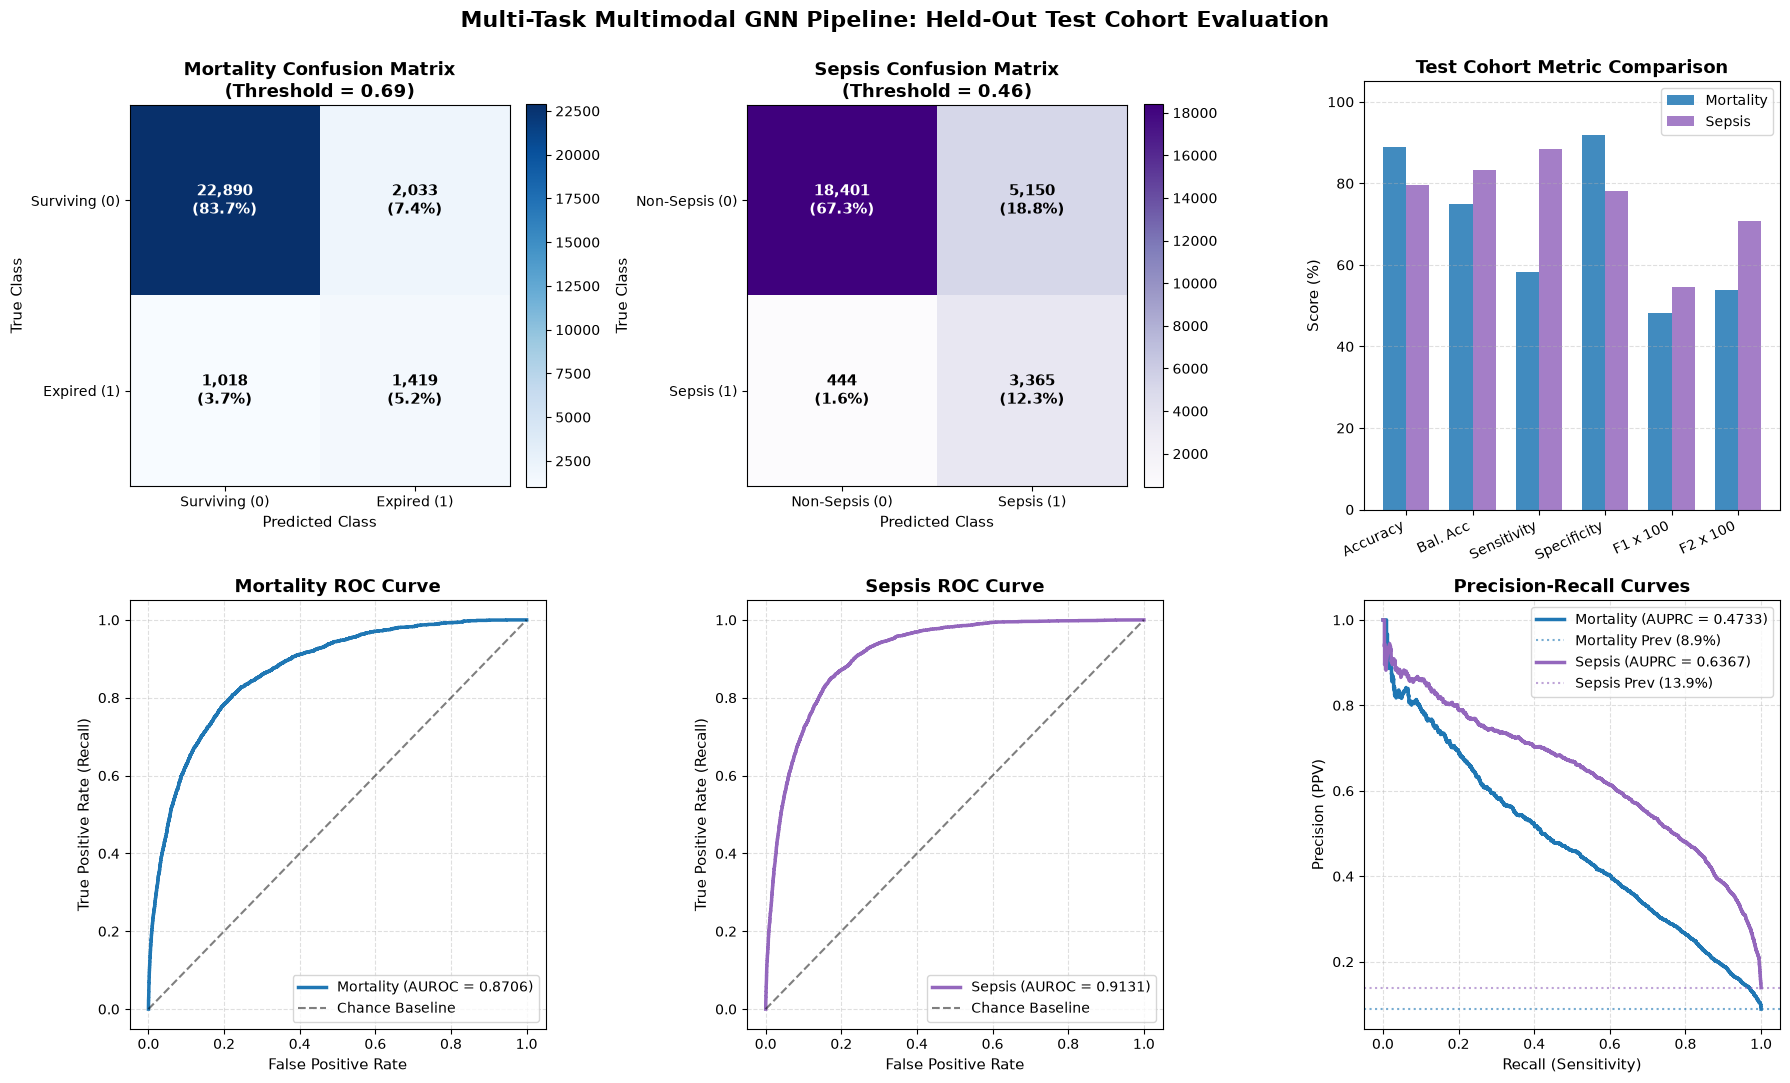

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Multi-Task Multimodal GNN Pipeline: Held-Out Test Cohort Evaluation", fontsize=16, fontweight="bold", y=0.98)

# 1. Confusion Matrix: Mortality
cm_m = np.array(test_mort_metrics["confusion_matrix"])
im0 = axes[0, 0].imshow(cm_m, cmap="Blues", interpolation="nearest")
axes[0, 0].set_title(f"Mortality Confusion Matrix\n(Threshold = {thresh_mort:.2f})", fontsize=13, fontweight="semibold")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_yticks([0, 1])
axes[0, 0].set_xticklabels(["Surviving (0)", "Expired (1)"])
axes[0, 0].set_yticklabels(["Surviving (0)", "Expired (1)"])
axes[0, 0].set_xlabel("Predicted Class", fontsize=11)
axes[0, 0].set_ylabel("True Class", fontsize=11)
for i in range(2):
    for j in range(2):
        count = cm_m[i, j]
        pct = count / cm_m.sum() * 100
        axes[0, 0].text(
            j, i, f"{count:,}\n({pct:.1f}%)", ha="center", va="center",
            color="white" if cm_m[i, j] > cm_m.max() / 2 else "black", fontsize=11, fontweight="bold"
        )
fig.colorbar(im0, ax=axes[0, 0], fraction=0.046, pad=0.04)

# 2. Confusion Matrix: Sepsis
cm_s = np.array(test_seps_metrics["confusion_matrix"])
im1 = axes[0, 1].imshow(cm_s, cmap="Purples", interpolation="nearest")
axes[0, 1].set_title(f"Sepsis Confusion Matrix\n(Threshold = {thresh_seps:.2f})", fontsize=13, fontweight="semibold")
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_yticks([0, 1])
axes[0, 1].set_xticklabels(["Non-Sepsis (0)", "Sepsis (1)"])
axes[0, 1].set_yticklabels(["Non-Sepsis (0)", "Sepsis (1)"])
axes[0, 1].set_xlabel("Predicted Class", fontsize=11)
axes[0, 1].set_ylabel("True Class", fontsize=11)
for i in range(2):
    for j in range(2):
        count = cm_s[i, j]
        pct = count / cm_s.sum() * 100
        axes[0, 1].text(
            j, i, f"{count:,}\n({pct:.1f}%)", ha="center", va="center",
            color="white" if cm_s[i, j] > cm_s.max() / 2 else "black", fontsize=11, fontweight="bold"
        )
fig.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

# 3. Metric Comparison Bar Chart across tasks
metric_labels = ["Accuracy", "Bal. Acc", "Sensitivity", "Specificity", "F1 x 100", "F2 x 100"]
m_vals = [
    test_mort_metrics["accuracy"], test_mort_metrics["balanced_accuracy"],
    test_mort_metrics["recall_sensitivity"], test_mort_metrics["specificity"],
    test_mort_metrics["f1"] * 100, test_mort_metrics["f2"] * 100,
]
s_vals = [
    test_seps_metrics["accuracy"], test_seps_metrics["balanced_accuracy"],
    test_seps_metrics["recall_sensitivity"], test_seps_metrics["specificity"],
    test_seps_metrics["f1"] * 100, test_seps_metrics["f2"] * 100,
]

x_idx = np.arange(len(metric_labels))
width = 0.35
axes[0, 2].bar(x_idx - width/2, m_vals, width, label="Mortality", color="#1f77b4", alpha=0.85)
axes[0, 2].bar(x_idx + width/2, s_vals, width, label="Sepsis", color="#9467bd", alpha=0.85)
axes[0, 2].set_title("Test Cohort Metric Comparison", fontsize=13, fontweight="semibold")
axes[0, 2].set_xticks(x_idx)
axes[0, 2].set_xticklabels(metric_labels, rotation=25, ha="right", fontsize=10)
axes[0, 2].set_ylabel("Score (%)", fontsize=11)
axes[0, 2].set_ylim(0, 105)
axes[0, 2].legend(frameon=True)
axes[0, 2].grid(axis="y", linestyle="--", alpha=0.4)

# 4. ROC Curves
fpr_m, tpr_m, _ = roc_curve(test_data["mort_y"], test_data["mort_probs"])
fpr_s, tpr_s, _ = roc_curve(test_data["seps_y"], test_data["seps_probs"])
axes[1, 0].plot(fpr_m, tpr_m, color="#1f77b4", lw=2.5, label=f"Mortality (AUROC = {test_mort_metrics['auroc']:.4f})")
axes[1, 0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance Baseline")
axes[1, 0].set_title("Mortality ROC Curve", fontsize=13, fontweight="semibold")
axes[1, 0].set_xlabel("False Positive Rate", fontsize=11)
axes[1, 0].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[1, 0].legend(loc="lower right", frameon=True)
axes[1, 0].grid(linestyle="--", alpha=0.4)

axes[1, 1].plot(fpr_s, tpr_s, color="#9467bd", lw=2.5, label=f"Sepsis (AUROC = {test_seps_metrics['auroc']:.4f})")
axes[1, 1].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance Baseline")
axes[1, 1].set_title("Sepsis ROC Curve", fontsize=13, fontweight="semibold")
axes[1, 1].set_xlabel("False Positive Rate", fontsize=11)
axes[1, 1].set_ylabel("True Positive Rate (Recall)", fontsize=11)
axes[1, 1].legend(loc="lower right", frameon=True)
axes[1, 1].grid(linestyle="--", alpha=0.4)

# 5. Precision-Recall Curves
prec_m, rec_m, _ = precision_recall_curve(test_data["mort_y"], test_data["mort_probs"])
prec_s, rec_s, _ = precision_recall_curve(test_data["seps_y"], test_data["seps_probs"])
prev_m = float(np.mean(test_data["mort_y"]))
prev_s = float(np.mean(test_data["seps_y"]))

axes[1, 2].plot(rec_m, prec_m, color="#1f77b4", lw=2.5, label=f"Mortality (AUPRC = {test_mort_metrics['auprc']:.4f})")
axes[1, 2].axhline(prev_m, color="#1f77b4", linestyle=":", alpha=0.6, label=f"Mortality Prev ({prev_m*100:.1f}%)")
axes[1, 2].plot(rec_s, prec_s, color="#9467bd", lw=2.5, label=f"Sepsis (AUPRC = {test_seps_metrics['auprc']:.4f})")
axes[1, 2].axhline(prev_s, color="#9467bd", linestyle=":", alpha=0.6, label=f"Sepsis Prev ({prev_s*100:.1f}%)")
axes[1, 2].set_title("Precision-Recall Curves", fontsize=13, fontweight="semibold")
axes[1, 2].set_xlabel("Recall (Sensitivity)", fontsize=11)
axes[1, 2].set_ylabel("Precision (PPV)", fontsize=11)
axes[1, 2].legend(loc="upper right", frameon=True)
axes[1, 2].grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plot_path = FIGURES_DIR / "multitask_evaluation_plots.png"
fig.savefig(plot_path, dpi=300, bbox_inches="tight")
print(f"Saved diagnostic plots to: {plot_path}")
plt.show()


## 9. Save Metrics and Export Summary

In [33]:
metrics_export = {
    "model": "end_to_end_multimodal_multitask_pipeline",
    "best_epoch": int(ckpt["best_epoch"]),
    "val_mean_auprc": float(ckpt["best_mean_val_auprc"]),
    "threshold_mortality": float(thresh_mort),
    "threshold_sepsis": float(thresh_seps),
    "test_mortality_metrics": test_mort_metrics,
    "test_sepsis_metrics": test_seps_metrics,
    "cross_phase_progression": phase_rows,
}

with open(OUT_DIR / "metrics.json", "w") as f:
    json.dump(metrics_export, f, indent=2)
print(f"Saved metrics to: {OUT_DIR / 'metrics.json'}")

np.savez_compressed(
    OUT_DIR / "test_predictions.npz",
    mort_probs=test_data["mort_probs"],
    mort_y=test_data["mort_y"],
    seps_probs=test_data["seps_probs"],
    seps_y=test_data["seps_y"],
    pids=test_data["pids"],
)
print(f"Saved predictions to: {OUT_DIR / 'test_predictions.npz'}")


Saved metrics to: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/multitask/metrics.json
Saved predictions to: /Users/aryandwivedi/Desktop/Project Hail Minor/checkpoints/fusion/multitask/test_predictions.npz
